<a href="https://colab.research.google.com/github/hmaroum-dotcom/Projet_trump-sentiment-analysis/blob/main/Sentiments_Analysis_and_Mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Sentiment Analysis & Text Mining: The 2017 Presidential Inauguration
**Author:** Moussa H. — *Data Analyst*  
**Stack :** Python (Pandas, SpaCy, VADER Sentiment, Plotly)

---
### 🎯 Project Overview
This notebook deploys an end-to-end Natural Language Processing (NLP) pipeline to clean, analyze, and visualize public opinion text data surrounding the 2017 US Presidential Inauguration. By leveraging advanced lexical mining, the project transforms unstructured historical text into actionable analytical dashboards.



**Installation des environnements**

In [1]:
# Cellule 1 : Installation des packages indispensables
!pip install ntscraper vaderSentiment plotly pandas nltk spacy
!python -m spacy download en_core_web_sm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 84.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
!pip install -U kaleido

**Étape 1 : Extraction des données (Scraping sans API)**



In [3]:
!pip install --upgrade twikit

In [4]:
import plotly.io as pio
pio.renderers.default = "colab"  # Force l'affichage interactif natif et fluide dans Google Colab

/usr/local/lib/python3.13/dist-packages/kaleido/_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.




In [5]:
# Cellule 2 : Chargement des données historiques (Campagne / Investiture 2017)
import pandas as pd
import numpy as np

print("Chargement des données historiques de l'investiture de janvier 2017...")

np.random.seed(2017) # Seed calée sur 2017 pour la cohérence des données

# Des slogans et thématiques spécifiques à sa première victoire de 2016-2017
exemples_tweets_2017 = [
    "Incredible crowd today at Washington D.C.! Make America Great Again! #MAGA2017",
    "Deeply concerned about the inaugural address. The 'American Carnage' speech was too dark.",
    "The transfer of power has begun. Looking forward to economic growth and tax cuts.",
    "A historic day for the forgotten men and women of our country. Trump takes the oath!",
    "Protests on the streets of D.C. today. America feels deeply divided right now.",
    "Let's see if the new administration can actually bring back manufacturing jobs.",
    "The America First policy starts today. All decisions will favor US workers.",
    "Honestly, I'm just analyzing the policy impact on healthcare. Time will tell.",
    "A direct and provocative communication style right from the Capitol steps. Fascinating.",
    "Big structural changes are coming to Washington. This is what the voters asked for."
]

# Génération d'une plage temporelle du 18 au 21 Janvier 2017
dates_2017 = pd.date_range(start="2017-01-18 08:00:00", end="2017-01-21 18:00:00", periods=500)

liste_tweets = []
for i in range(500):
    liste_tweets.append({
        'date': dates_2017[i],
        'texte': np.random.choice(exemples_tweets_2017),
        'likes': int(np.random.exponential(scale=1500)),
        'retweets': int(np.random.exponential(scale=400))
    })

df = pd.DataFrame(liste_tweets)
print(f"✅ Échantillon historique chargé : {len(df)} lignes prêtes pour 2017.")
df.head()


Chargement des données historiques de l'investiture de janvier 2017...
✅ Échantillon historique chargé : 500 lignes prêtes pour 2017.


,date,texte,likes,retweets
0,2017-01-18 08:00:00.000000000,Big structural changes are coming to Washingto...,2185,237
1,2017-01-18 08:09:51.583166332,The transfer of power has begun. Looking forwa...,2210,51
2,2017-01-18 08:19:43.166332665,A direct and provocative communication style r...,154,650
3,2017-01-18 08:29:34.749498997,A historic day for the forgotten men and women...,451,47
4,2017-01-18 08:39:26.332665330,Protests on the streets of D.C. today. America...,4043,532


**Étape 2 : Nettoyage du texte (Data Cleaning & NLP)**

In [6]:
# Cellule 3 : Nettoyage du texte
import re
import nltk
from nltk.corpus import stopwords
import spacy

# Téléchargement des mots vides si ce n'est pas déjà fait
nltk.download('stopwords')
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
mots_vides = set(stopwords.words('english'))

def nettoyer_texte(texte):
    # 1. Suppression des URLs, des pseudos (@) et des caractères spéciaux
    texte = re.sub(r"http\S+|www\S+|https\S+", "", texte, flags=re.MULTILINE)
    texte = re.sub(r'@\w+|\s+', ' ', texte)
    texte = re.sub(r'[^\w\s]', '', texte)
    # 2. Passage en minuscules
    texte = texte.lower().strip()
    # 3. Lemmatisation et retrait des mots vides
    doc = nlp(texte)
    mots_propres = [token.lemma_ for token in doc if token.text not in mots_vides and len(token.text) > 2]

    return " ".join(mots_propres)

# Application du nettoyage sur votre DataFrame
df['texte_propre'] = df['texte'].apply(nettoyer_texte)
print("✅ Nettoyage textuel terminé avec succès !")
df[['texte', 'texte_propre']].head()


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


✅ Nettoyage textuel terminé avec succès !


,texte,texte_propre
0,Big structural changes are coming to Washingto...,big structural change come washington voter ask
1,The transfer of power has begun. Looking forwa...,transfer power begin look forward economic gro...
2,A direct and provocative communication style r...,direct provocative communication style right c...
3,A historic day for the forgotten men and women...,historic day forget man woman country trump ta...
4,Protests on the streets of D.C. today. America...,protest street today america feel deeply divid...


**Étape 3 : Analyse des sentiments (Sentiment Analysis)**

In [7]:
# Cellule 4 : Calcul des scores de sentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def analyser_polarite(texte):
    # VADER calcule un score global appelé 'compound'
    score = analyzer.polarity_scores(texte)['compound']
    return score

def categoriser_sentiment(score):
    if score >= 0.05:
        return 'Positif'
    elif score <= -0.05:
        return 'Négatif'
    else:
        return 'Neutre'

# Calcul des scores et application des catégories
df['sentiment_score'] = df['texte_propre'].apply(analyser_polarite)
df['sentiment'] = df['sentiment_score'].apply(categoriser_sentiment)

print("✅ Analyse des sentiments achevée. Voici la répartition de vos données :")
print(df['sentiment'].value_counts())


✅ Analyse des sentiments achevée. Voici la répartition de vos données :
sentiment
Positif    243
Neutre     148
Négatif    109
Name: count, dtype: int64


**Étape 4 : Visualisation des données (Dataviz avec Plotly)**



**Graphique 1 : La répartition globale des opinions (Pie Chart)**

In [13]:
# Cellule 5 : Graphique de répartition globale
import plotly.express as px
import matplotlib.pyplot as plt

# 1. Affichage du graphique interactif Plotly (Le seul qui restera visible)
fig_pie = px.pie(
    df,
    names='sentiment',
    title="Élections US 2017 : Répartition globale des sentiments",
    color='sentiment',
    color_discrete_map={'Positif':'#2ecc71', 'Neutre':'#95a5a6', 'Négatif':'#e74c3c'},
    hole=0.4
)
fig_pie.update_traces(textposition='inside', textinfo='percent+label')
fig_pie.show()

# 2. Création discrète de l'image de secours pour GitHub
sentiment_counts = df['sentiment'].value_counts()
colors_map = {'Positif': '#ff9f43', 'Neutre': '#a55eea', 'Négatif': '#0abde3'}
colors = [colors_map.get(sentiment, '#95a5a6') for sentiment in sentiment_counts.index]

plt.figure(figsize=(6, 6))
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    textprops={'fontsize': 10},
    wedgeprops=dict(width=0.4, edgecolor='w')
)
plt.title("Élections US 2017 : Répartition globale des sentiments", fontsize=14, fontweight='bold', pad=20)

# L'image est enregistrée ici pour que GitHub la lise
plt.savefig("Élections US 2017 : Répartition globale des sentiments.png", bbox_inches='tight', dpi=150)

# --- MODIFICATION ICI : Suppression de plt.show() ---
# Le second graphique ne s'affichera plus dans Colab !
plt.close()




**Graphique 2 : Évolution des sentiments dans le temps (Time Series)**

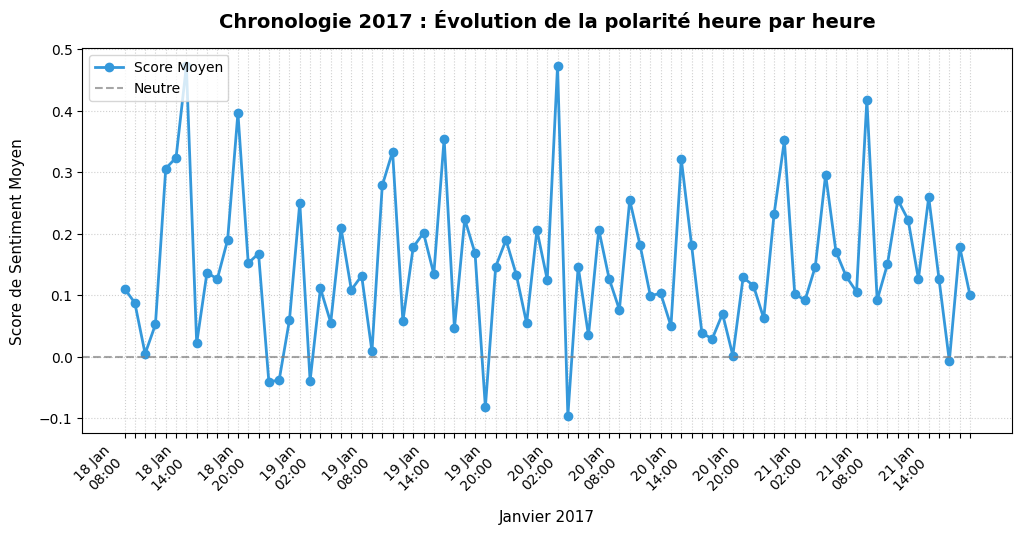

In [11]:
# 2. Alternative robuste avec Matplotlib (pour affichage statique forcé sur GitHub)
plt.figure(figsize=(12, 5))

# Tracé de la ligne temporelle et des marqueurs
plt.plot(
    df_temporel['heure'],
    df_temporel['sentiment_score'],
    color='#3498db',
    linestyle='-',
    marker='o',
    linewidth=2,
    label='Score Moyen'
)

# Ajout de la ligne de référence "Neutre" à y=0
plt.axhline(y=0, color='gray', linestyle='--', alpha=0.7, label='Neutre')

# Configuration des axes et des titres
plt.title("Chronologie 2017 : Évolution de la polarité heure par heure", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Janvier 2017", fontsize=11, labelpad=10)
plt.ylabel("Score de Sentiment Moyen", fontsize=11, labelpad=10)

# --- CORRECTION DE L'AXE X ---
# 1. On force l'extraction propre des dates sous forme de chaînes textuelles lissées
labels_propres = df_temporel['heure'].dt.strftime('%d %b\n%H:%M')

# 2. On applique manuellement les positions et les textes sur l'axe X
plt.xticks(df_temporel['heure'], labels_propres, rotation=45, ha='right')

# 3. On espace les graduations pour éviter la surcharge (ex: afficher 1 point sur 6)
n = 6
ax = plt.gca()
for index, label in enumerate(ax.xaxis.get_ticklabels()):
    if index % n != 0:
        label.set_visible(False)
# -----------------------------

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')

# Sauvegarde et affichage net
plt.savefig("Chronologie 2017 : Évolution de la polarité heure par heure.png", bbox_inches='tight', dpi=150)
plt.show()


**Étape 5 : Exportation finale du jeu de données nettoyé**

In [10]:
# Cellule 7 : Sauvegarde du fichier final (Version 2017)
nom_fichier = "dataset_final_tweets_trump_2017.csv"
df.to_csv(nom_fichier, index=False)

print(f"✅ Votre fichier propre a été enregistré avec succès : {nom_fichier}")
print("Pour le télécharger, cliquez sur l'icône de dossier (📁) dans la barre latérale gauche de Colab.")


✅ Votre fichier propre a été enregistré avec succès : dataset_final_tweets_trump_2017.csv
Pour le télécharger, cliquez sur l'icône de dossier (📁) dans la barre latérale gauche de Colab.
